### 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

/opt/anaconda3/envs/conda_virtual/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2.Load dataset

In [2]:
emotion_dataset =load_dataset("dair-ai/emotion")
# https://huggingface.co/datasets/dair-ai/emotion
train_text  = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text  = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [3]:
label_name = emotion_dataset['train'].features['label'].names
label_name

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [4]:
# for i in train_label:
#     print(label_name[i])

In [5]:
df_train = pd.DataFrame({
    'text'  : train_text,
    'label' : [label_name[i] for i in train_label]
})

df_test = pd.DataFrame({
    'text'  : test_text,
    'label' : [label_name[i] for i in test_label]
})

In [6]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


### 3.EDA

In [7]:
df_train.isnull().sum()
df_test.isnull().sum()

text     0
label    0
dtype: int64

In [8]:
df_train['label'].value_counts()

label
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

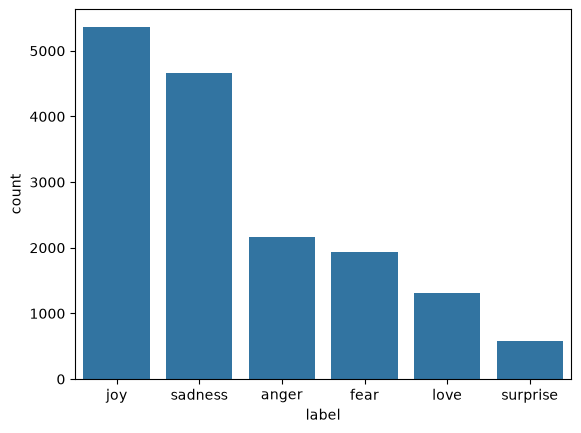

In [9]:
sns.countplot(x=df_train['label'],order=df_train['label'].value_counts().index)
plt.show()

### 4.Data Preprocessing -Using NLP

In [10]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 15000

tokenizer = Tokenizer(num_words=max_words,oov_token='<unk>')

tokenizer.fit_on_texts(df_train['text'])
"""
'i feel humilated' -> ['i' : 1, 'feel' : 2, 'humilated' :30]
"""

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence  = tokenizer.texts_to_sequences(df_test['text'])


padded_train_sequence = pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence = pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')

padded_train_sequence

train_labels = np.array(train_label)
test_labels   = np.array(test_label)
train_label

num_class = len(np.unique(train_label))

print("Vocabulary size:",len(tokenizer.word_index))
print("Max Sentences Length:",padded_train_sequence.shape[1])


Vocabulary size: 15213
Max Sentences Length: 50


In [11]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight= 'balanced',
    classes= np.unique(train_labels),
    y = train_labels
)

class_weight_dect = dict(enumerate(class_weights))
class_weight_dect

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [12]:
from tensorflow.keras.callbacks import EarlyStopping

earlyStopping = EarlyStopping(
    monitor= 'val_loss',
    patience= 3,
    restore_best_weights= True
)

### 6.Phase 1 Foundational Model

simple RNN, LSTM, GRU

#### 6.1 Simple RNN

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Embedding,Dense,Dropout,LSTM,GRU

In [14]:
Simple_RNN_Model = Sequential()

Simple_RNN_Model.add(Embedding(input_dim=max_words,output_dim=128,input_length=50))
Simple_RNN_Model.add(SimpleRNN(units=128,return_sequences=True))
Simple_RNN_Model.add(Dropout(0.5))
Simple_RNN_Model.add(SimpleRNN(units=64))
Simple_RNN_Model.add(Dropout(0.5))
Simple_RNN_Model.add(Dense(units=num_class,activation='softmax'))

Simple_RNN_Model.summary()

/opt/anaconda3/envs/conda_virtual/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [16]:
Simple_RNN_Model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

History_1 = Simple_RNN_Model.fit(padded_train_sequence,train_labels,
                               validation_data=(padded_test_sequence,test_labels),
                               epochs =20,batch_size = 32,
                               class_weight = class_weight_dect,
                               callbacks = [earlyStopping])

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.1433 - loss: 1.9213 - val_accuracy: 0.1225 - val_loss: 1.7925
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.1339 - loss: 1.8376 - val_accuracy: 0.3230 - val_loss: 1.7566
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.1376 - loss: 1.8096 - val_accuracy: 0.1340 - val_loss: 1.7968
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.1324 - loss: 1.8042 - val_accuracy: 0.2715 - val_loss: 1.7904
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - accuracy: 0.1400 - loss: 1.8045 - val_accuracy: 0.3490 - val_loss: 1.7798


In [17]:
Simple_RNN_test_loss,Simple_RNN_test_accuracy = Simple_RNN_Model.evaluate(padded_test_sequence,test_labels)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3230 - loss: 1.7566


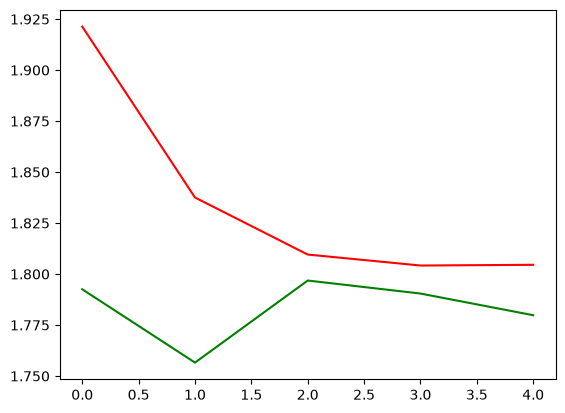

In [18]:
plt.plot(History_1.history['loss'],color = 'red')
plt.plot(History_1.history['val_loss'],color = 'green')
plt.show()

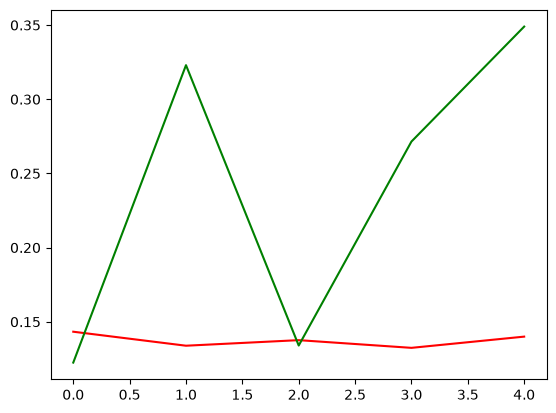

In [20]:
plt.plot(History_1.history['accuracy'], color = 'red')
plt.plot(History_1.history['val_accuracy'],color = 'green')
plt.show()

6.2 LSTM

In [21]:
LSTM_Model = Sequential()

LSTM_Model.add(Embedding(input_dim=max_words,output_dim=128,input_length=50))
LSTM_Model.add(LSTM(units=128,return_sequences=True))
LSTM_Model.add(Dropout(0.5))
LSTM_Model.add(LSTM(units=64))
LSTM_Model.add(Dropout(0.5))
LSTM_Model.add(Dense(units=num_class,activation='softmax'))

LSTM_Model.summary()


LSTM_Model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

History_2 = LSTM_Model.fit(padded_train_sequence,train_labels,
                               validation_data=(padded_test_sequence,test_labels),
                               epochs =20,batch_size = 32,
                               class_weight = class_weight_dect,
                               callbacks = [earlyStopping])



/opt/anaconda3/envs/conda_virtual/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 19s 36ms/step - accuracy: 0.1646 - loss: 1.7951 - val_accuracy: 0.0795 - val_loss: 1.8097
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1564 - loss: 1.7944 - val_accuracy: 0.0830 - val_loss: 1.7990
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.1569 - loss: 1.7930 - val_accuracy: 0.1810 - val_loss: 1.7858
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1922 - loss: 1.7762 - val_accuracy: 0.1390 - val_loss: 1.8291
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.2579 - loss: 1.5468 - val_accuracy: 0.3380 - val_loss: 1.4244
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.4205 - loss: 1.1004 - val_accuracy: 0.5120 - val_loss: 1.1164
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.5877 - loss: 0.6774 - val_accuracy: 0.5710 - val_loss: 0.8756
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 33ms/step - accuracy: 0.6720 - loss: 0.5372 - 

In [22]:
LSTM_test_loss,LSTM_test_accuracy= LSTM_Model.evaluate(padded_test_sequence,test_labels)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8950 - loss: 0.4335


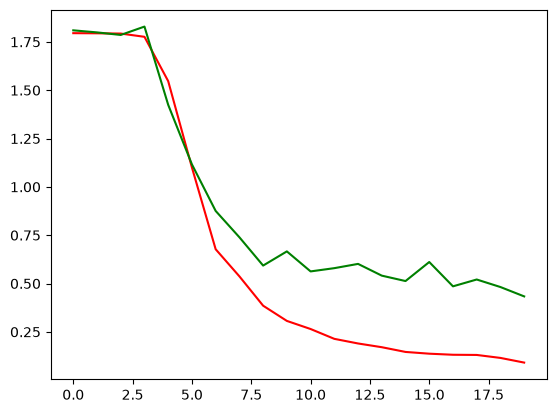

In [23]:
plt.plot(History_2.history['loss'],color = 'red')
plt.plot(History_2.history['val_loss'],color = 'green')
plt.show()

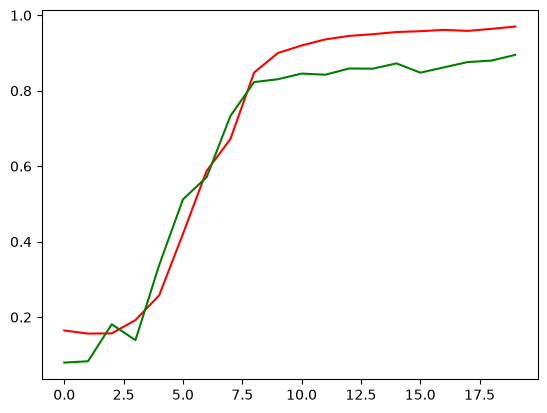

In [24]:
plt.plot(History_2.history['accuracy'], color = 'red')
plt.plot(History_2.history['val_accuracy'],color = 'green')
plt.show()

In [30]:
GRU_Model = Sequential()

GRU_Model.add(Embedding(input_dim=max_words,output_dim=128,input_length=50))
GRU_Model.add(GRU(units=128,return_sequences=True))
GRU_Model.add(Dropout(0.5))
GRU_Model.add(GRU(units=64))
GRU_Model.add(Dropout(0.5))
GRU_Model.add(Dense(units=num_class,activation='softmax'))

GRU_Model.summary()


GRU_Model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

History_3 = GRU_Model.fit(padded_train_sequence,train_labels,
                               validation_data=(padded_test_sequence,test_labels),
                               epochs =20,batch_size = 32,
                               class_weight = class_weight_dect,
                               callbacks = [earlyStopping])



/opt/anaconda3/envs/conda_virtual/lib/python3.13/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_5 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_6 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.1566 - loss: 1.7964 - val_accuracy: 0.1420 - val_loss: 1.7923
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 16s 32ms/step - accuracy: 0.1538 - loss: 1.7949 - val_accuracy: 0.0800 - val_loss: 1.7976
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.1620 - loss: 1.7944 - val_accuracy: 0.2900 - val_loss: 1.8024
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 29ms/step - accuracy: 0.1570 - loss: 1.7933 - val_accuracy: 0.3415 - val_loss: 1.7817
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1699 - loss: 1.7873 - val_accuracy: 0.1385 - val_loss: 1.7689
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 31ms/step - accuracy: 0.1768 - loss: 1.7658 - val_accuracy: 0.0900 - val_loss: 1.8207
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 14s 29ms/step - accuracy: 0.2141 - loss: 1.7128 - val_accuracy: 0.1710 - val_loss: 1.8342
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 15s 30ms/step - accuracy: 0.2577 - loss: 1.6117 - 

In [31]:
GRU_test_loss,GRU_test_accuracy= GRU_Model.evaluate(padded_test_sequence,test_labels)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1385 - loss: 1.7689


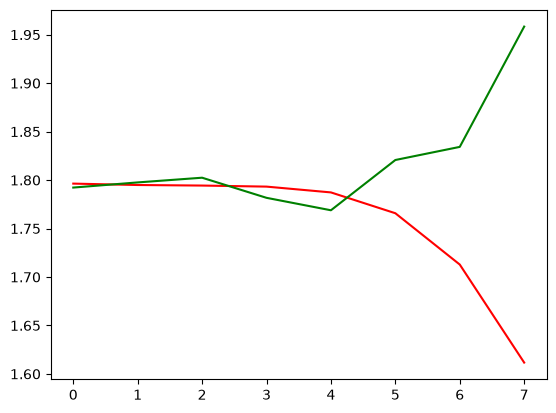

In [32]:
plt.plot(History_3.history['loss'],color = 'red')
plt.plot(History_3.history['val_loss'],color = 'green')
plt.show()

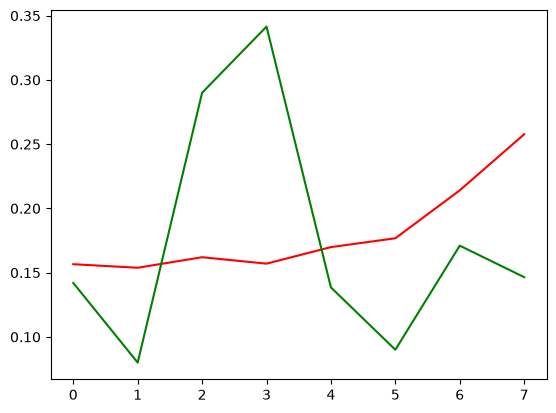

In [33]:
plt.plot(History_3.history['accuracy'], color = 'red')
plt.plot(History_3.history['val_accuracy'],color = 'green')
plt.show()

In [34]:
result_df = pd.DataFrame({
    'Mode'           : ['RNN','LSTM','GRU'],
    'Test_Loss'      : [Simple_RNN_test_loss,LSTM_test_loss,GRU_test_loss],
    'Test_Accuracy' : [Simple_RNN_test_accuracy,LSTM_test_accuracy,GRU_test_accuracy] 
}).sort_values(by='Test_Accuracy',ascending=False)

In [35]:
result_df

,Mode,Test_Loss,Test_Accuracy
1,LSTM,0.433514,0.8950
0,RNN,1.756591,0.3230
2,GRU,1.768850,0.1385


### 7. Phase 2 — Advanced Bidirectional GRU

Enhance GRU with Bidirectional layers, 300D embeddings, and 0.5 dropout regularization.

#### 7.1 Model 4 — Advanced Stacked Bidirectional GRU

In [38]:
from tensorflow.keras.layers import Bidirectional

Bi_GRU_Model = Sequential()

Bi_GRU_Model.add(Embedding(input_dim=max_words,output_dim=256,input_length=50))
Bi_GRU_Model.add(Bidirectional(GRU(units=128,return_sequences=True)))
Bi_GRU_Model.add(Dropout(0.6))
Bi_GRU_Model.add(Bidirectional(GRU(units=64)))
Bi_GRU_Model.add(Dropout(0.6))
Bi_GRU_Model.add(Dense(units=num_class,activation='softmax'))

Bi_GRU_Model.summary()


Bi_GRU_Model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

History_4 = Bi_GRU_Model.fit(padded_train_sequence,train_labels,
                               validation_data=(padded_test_sequence,test_labels),
                               epochs =20,batch_size = 32,
                               class_weight = class_weight_dect,
                               callbacks = [earlyStopping])


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_4 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_5 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 76ms/step - accuracy: 0.5222 - loss: 1.1442 - val_accuracy: 0.8775 - val_loss: 0.4039
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.9115 - loss: 0.2654 - val_accuracy: 0.9130 - val_loss: 0.2418
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 40s 81ms/step - accuracy: 0.9413 - loss: 0.1672 - val_accuracy: 0.9140 - val_loss: 0.2335
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.9617 - loss: 0.1123 - val_accuracy: 0.9180 - val_loss: 0.2305
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 81ms/step - accuracy: 0.9729 - loss: 0.0827 - val_accuracy: 0.9045 - val_loss: 0.3455
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 43s 86ms/step - accuracy: 0.9762 - loss: 0.0758 - val_accuracy: 0.9130 - val_loss: 0.3177
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.9774 - loss: 0.0686 - val_accuracy: 0.9220 - val_loss: 0.2999


### 8. Overall Evaluation & Bias Analysis

Consolidate test metrics, plot raw & normalized confusion matrices, and analyze bias.

#### 8.1 Final Model Confusion Matrices (Raw Counts & Normalized %)

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


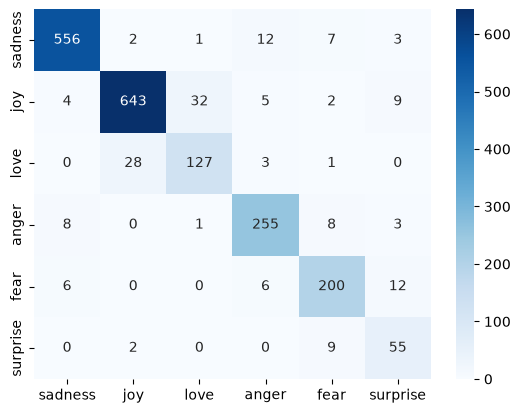

In [39]:
from sklearn.metrics import confusion_matrix

Bi_GRU_Pred = np.argmax(Bi_GRU_Model.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_labels,Bi_GRU_Pred),annot=True,fmt='d',cmap='Blues',xticklabels=label_name,yticklabels=label_name)
plt.show()

### 9.Prediction

In [40]:

sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
padded_sample_sequences = pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

sample_pred = np.argmax(Bi_GRU_Model.predict(padded_sample_sequences),axis=1)

for i in range(len(sample_texts)):
    print(f'Text: {sample_texts[i]} \n predicted Emotion :{label_name[sample_pred[i]]} ')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Text: I can't believe how happy I am right now, this is amazing! 
 predicted Emotion :surprise 
Text: I feel so alone and hopeless today. 
 predicted Emotion :sadness 
Text: I am furious that they cancelled the trip at the last minute. 
 predicted Emotion :anger 
Text: I feel terrified when walking down dark alleyways alone. 
 predicted Emotion :fear 
Text: I was shocked and completely surprised by the unexpected gift! 
 predicted Emotion :surprise 


### 10.Save Model and Tokenizer

In [42]:
import pickle
Bi_GRU_Model.save('Bi_GRU_Model.keras')

with open('tokenizer.pkl','wb') as file:
    pickle.dump(tokenizer,file)